# Pytorch Paper Replication

## 0. Getting Ready

In [1]:
# For this notebook to run with updated APIs, we need torch 1.12+ and torchvision 0.13+
try:
    import torch
    import torchvision
    assert int(torch.__version__.split(".")[1]) >= 12 or int(torch.__version__.split(".")[0]) == 2, "torch version should be 1.12+"
    assert int(torchvision.__version__.split(".")[1]) >= 13, "torchvision version should be 0.13+"
    print(f"torch version: {torch.__version__}")
    print(f"torchvision version: {torchvision.__version__}")
except:
    print(f"[INFO] torch/torchvision versions not as required, installing nightly versions.")
    !pip3 install -U torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
    import torch
    import torchvision
    print(f"torch version: {torch.__version__}")
    print(f"torchvision version: {torchvision.__version__}")

torch version: 2.14.0+cu130
torchvision version: 0.29.0+cu130


In [2]:
# Continue with regular imports
import matplotlib.pyplot as plt
import torch
import torchvision

from torch import nn
from torchvision import transforms

# Try to get torchinfo, install it if it doesn't work
try:
    from torchinfo import summary
except:
    print("[INFO] Couldn't find torchinfo... installing it.")
    !pip install -q torchinfo
    from torchinfo import summary

# Try to import the going_modular directory, download it from GitHub if it doesn't work
try:
    from going_modular.going_modular import data_setup, engine
    from helper_functions import download_data, set_seeds, plot_loss_curves
except:
    # Get the going_modular scripts
    print("[INFO] Couldn't find going_modular or helper_functions scripts... downloading them from GitHub.")
    !git clone https://github.com/mrdbourke/pytorch-deep-learning
    !mv pytorch-deep-learning/going_modular .
    !mv pytorch-deep-learning/helper_functions.py . # get the helper_functions.py script
    !rm -rf pytorch-deep-learning
    from going_modular.going_modular import data_setup, engine
    from helper_functions import download_data, set_seeds, plot_loss_curves

/home/rayaa/miniconda3/envs/yolov7/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## 1. Get Data

In [4]:
image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] data/pizza_steak_sushi directory exists, skipping download.


PosixPath('data/pizza_steak_sushi')

In [5]:
train_dir = image_path / "train"
test_dir = image_path / "test"

## 2. Create Dataset and DataLoader

### 2.1 Create Manual Transform

In [6]:
IMG_SIZE = 224

manual_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.ToTensor(),
])
print(f"Manual transforms:\n{manual_transforms}")

Manual transforms:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


### 2.1 Create dataloader

In [7]:
BATcH_SIZE = 32

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(
    train_dir=train_dir,
    test_dir=test_dir,
    transform=manual_transforms,
    batch_size=BATcH_SIZE
)

train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x74987c29f2e0>,
 ['pizza', 'steak', 'sushi'])

### 2.2 Visualize one Image

In [8]:
image_batch, label_batch = next(iter(train_dataloader))

image,label = image_batch[0], label_batch[0]

image.shape, label

(torch.Size([3, 224, 224]), tensor(2))

(-0.5, 223.5, 223.5, -0.5)

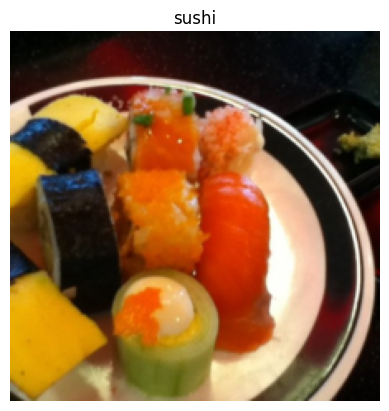

In [9]:
#Plot image with matplotlib
plt.imshow(image.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False)

## 3 About Paper Replicating

In this section mainly about the theories of the paper, You can read it in the website

## 4. Equation 1: Split data into patches and creating the class, position and patch embedding

### 4.1 Calculating patch embedding input and output shapes by hand

In [10]:
height = 224
width = 224
color_channels = 3
patch_size = 16

number_of_patches = int((height * width)/patch_size**2)
print(f"Number of patches (N) with image height (H={height}), width (W={width}) and patch size (P={patch_size}): {number_of_patches}")

Number of patches (N) with image height (H=224), width (W=224) and patch size (P=16): 196


In [11]:
embedding_layer_input_shape = (height, width, color_channels)
embedding_layer_output_shape = (number_of_patches, patch_size**2 * color_channels)

print(f"Input shape (single 2D image): {embedding_layer_input_shape}")
print(f"Output shape (single 2D image flattened into patches): {embedding_layer_output_shape}")

Input shape (single 2D image): (224, 224, 3)
Output shape (single 2D image flattened into patches): (196, 768)


### 4.2 Turning Single Image into Patches

(-0.5, 223.5, 223.5, -0.5)

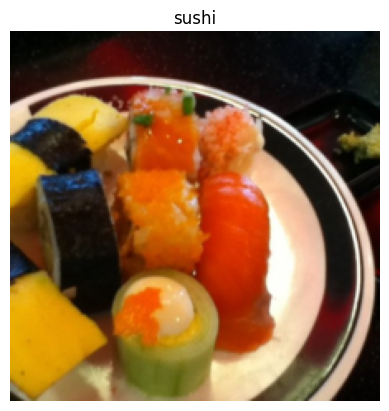

In [12]:
plt.imshow(image.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False)

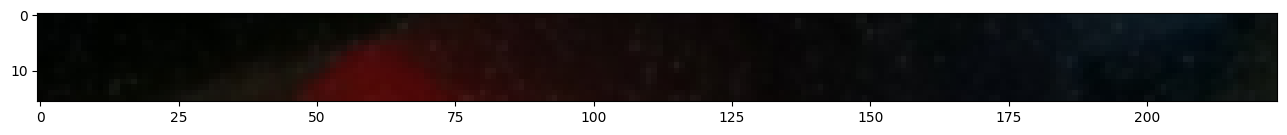

In [13]:
image_permuted = image.permute(1,2,0)

patch_size = 16
plt.figure(figsize=(patch_size,patch_size))
plt.imshow(image_permuted[:patch_size,:,:])

Number of patches per row: 14
Patch size: 16 pixels x 16 pixels


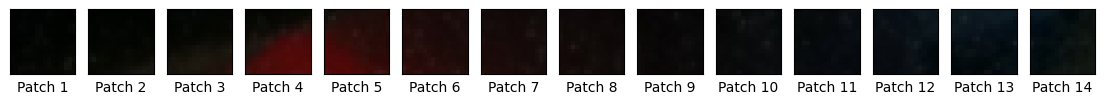

In [14]:
img_size = 224
patch_size = 16
num_patches = img_size // patch_size
assert img_size % patch_size == 0, "Image size must be divisible by patch size"
print(f"Number of patches per row: {num_patches}\nPatch size: {patch_size} pixels x {patch_size} pixels")

fig, axs = plt.subplots(nrows=1, ncols=img_size // patch_size,
                        figsize=(num_patches, num_patches),
                        sharex=True, sharey=True)

for i, patch in enumerate(range(0,img_size,patch_size)):
    axs[i].imshow(image_permuted[:patch_size,patch:patch+patch_size,:])
    axs[i].set_xlabel(f"Patch {i+1}")
    axs[i].set_xticks([])
    axs[i].set_yticks([])
    

Number of patches per row: 14.0        
Number of patches per column: 14.0        
Total patches: 196.0        
Patch size: 16 pixels x 16 pixels


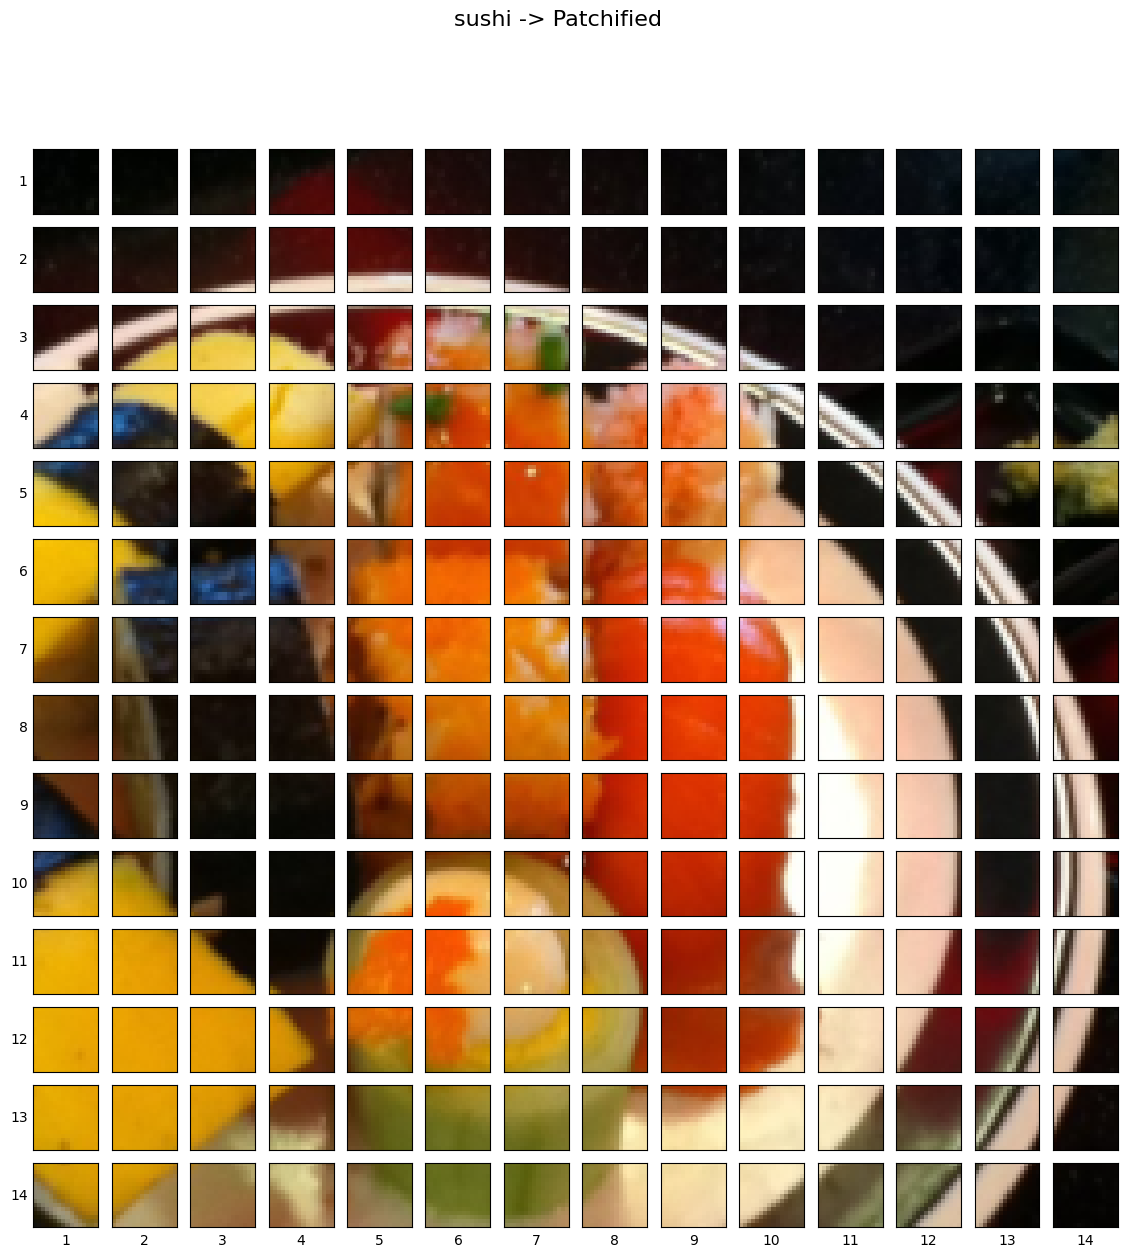

In [15]:
# Setup hyperparameters and make sure img_size and patch_size are compatible
img_size = 224
patch_size = 16
num_patches = img_size/patch_size
assert img_size % patch_size == 0, "Image size must be divisible by patch size"
print(f"Number of patches per row: {num_patches}\
        \nNumber of patches per column: {num_patches}\
        \nTotal patches: {num_patches*num_patches}\
        \nPatch size: {patch_size} pixels x {patch_size} pixels")

# Create a series of subplots
fig, axs = plt.subplots(nrows=img_size // patch_size, # need int not float
                        ncols=img_size // patch_size,
                        figsize=(num_patches, num_patches),
                        sharex=True,
                        sharey=True)

# Loop through height and width of image
for i, patch_height in enumerate(range(0, img_size, patch_size)): # iterate through height
    for j, patch_width in enumerate(range(0, img_size, patch_size)): # iterate through width

        # Plot the permuted image patch (image_permuted -> (Height, Width, Color Channels))
        axs[i, j].imshow(image_permuted[patch_height:patch_height+patch_size, # iterate through height
                                        patch_width:patch_width+patch_size, # iterate through width
                                        :]) # get all color channels

        # Set up label information, remove the ticks for clarity and set labels to outside
        axs[i, j].set_ylabel(i+1,
                             rotation="horizontal",
                             horizontalalignment="right",
                             verticalalignment="center")
        axs[i, j].set_xlabel(j+1)
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])
        axs[i, j].label_outer()

# Set a super title
fig.suptitle(f"{class_names[label]} -> Patchified", fontsize=16)
plt.show()

### 4.3 Creating Image Patches with torch.nn.Conv2d()

In [16]:
# we can patch with convolutional layer with kernel_size dan stride = patch_size
from torch import nn

patch_size = 16

conv2d = nn.Conv2d(in_channels=3,
                   out_channels=768,
                   kernel_size=patch_size,
                   stride=patch_size,
                   padding=0)

In [17]:
# Pass the image through the convolutional layer
image_out_of_conv = conv2d(image.unsqueeze(0)) # add a single batch dimension (height, width, color_channels) -> (batch, height, width, color_channels)
print(image_out_of_conv.shape)

torch.Size([1, 768, 14, 14])


Showing random convolutional feature maps from indexes: [407, 441, 393, 200, 589]


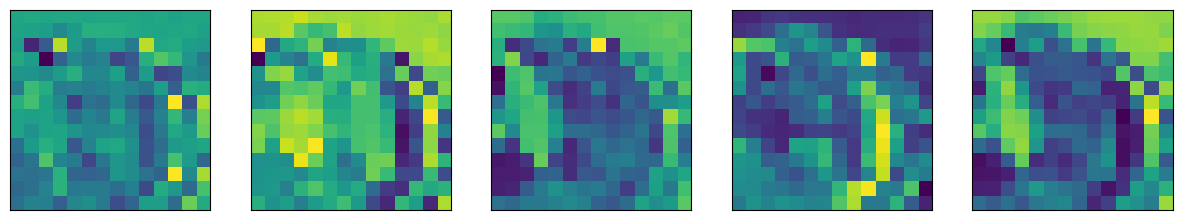

In [18]:
import random
random_indexes = random.sample(range(0,768),k=5)
print(f"Showing random convolutional feature maps from indexes: {random_indexes}")

fig,axs = plt.subplots(nrows=1, ncols=len(random_indexes),figsize=(15,15))

for i, idx in enumerate(random_indexes):
    image_conv_feature_map = image_out_of_conv[:,idx,:,:]
    axs[i].imshow(image_conv_feature_map.squeeze().detach().numpy())
    axs[i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

In [19]:
single_feature_map = image_out_of_conv[:,0,:,:]
single_feature_map, single_feature_map.requires_grad,single_feature_map.shape


(tensor([[[-0.0216, -0.0395, -0.0401, -0.0493, -0.0359, -0.0182, -0.0362,
           -0.0297, -0.0313, -0.0343, -0.0402, -0.0330, -0.0382, -0.0569],
          [-0.0186, -0.0341, -0.0698, -0.0775, -0.1311, -0.1721, -0.1067,
           -0.0351, -0.0310, -0.0367, -0.0423, -0.0328, -0.0337, -0.0399],
          [-0.3438,  0.1840, -0.1447, -0.1492, -0.0889,  0.0112,  0.0011,
           -0.1077,  0.1566, -0.1547, -0.0348, -0.0222, -0.0279, -0.0172],
          [ 0.1074,  0.0491, -0.0023, -0.0028,  0.0314, -0.0548, -0.0327,
            0.1089, -0.0352, -0.1397,  0.0116, -0.0468, -0.0438, -0.0648],
          [ 0.0291, -0.0135,  0.0187,  0.0238,  0.1865,  0.0398,  0.0364,
            0.0112,  0.0080, -0.1056,  0.1551, -0.0214,  0.0045, -0.0649],
          [-0.0178, -0.1171, -0.0581,  0.0217, -0.0239,  0.0421,  0.0046,
           -0.0158, -0.0070, -0.0280, -0.0925,  0.1380, -0.1932, -0.0305],
          [ 0.0537,  0.0098, -0.0248,  0.0248, -0.0158,  0.0219, -0.0048,
            0.1236,  0.0080, -0.

## 4.4 Flattening the patch Embedding

In [20]:
# Current tensor shape
print(f"Current tensor shape: {image_out_of_conv.shape} -> [batch, embedding_dim, feature_map_height, feature_map_width]")

Current tensor shape: torch.Size([1, 768, 14, 14]) -> [batch, embedding_dim, feature_map_height, feature_map_width]


In [21]:
# Create flatten layer
flatten = nn.Flatten(start_dim=2, # flatten feature_map_height (dimension 2)
                     end_dim=3) # flatten feature_map_width (dimension 3)

Original image shape: torch.Size([3, 224, 224]) -> [height, width, color_channels]
Image shape after convolutional layer: torch.Size([1, 768, 14, 14]) -> [batch, embedding_dim, feature_map_height, feature_map_width]
Image shape after flattening: torch.Size([1, 768, 196]) -> [batch, embedding_dim, feature_map_height * feature_map_width]


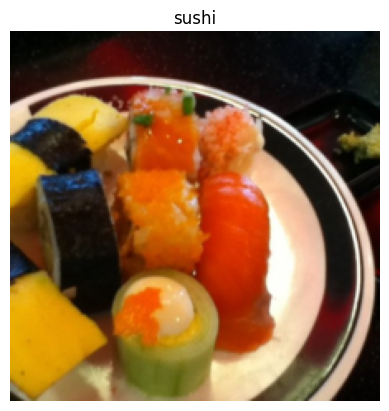

In [22]:
plt.imshow(image.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False)
print(f"Original image shape: {image.shape} -> [height, width, color_channels]")

# turn into feature maps
image_out_of_conv = conv2d(image.unsqueeze(0)) # add a single batch dimension (height, width, color_channels) -> (batch, height, width, color_channels)
print(f"Image shape after convolutional layer: {image_out_of_conv.shape} -> [batch, embedding_dim, feature_map_height, feature_map_width]")

# flatten the feature maps
image_out_of_conv_flattened = flatten(image_out_of_conv)
print(f"Image shape after flattening: {image_out_of_conv_flattened.shape} -> [batch, embedding_dim, feature_map_height * feature_map_width]")

In [23]:
# Get flattened image patch embeddings in right shape
image_out_of_conv_flattened_reshaped = image_out_of_conv_flattened.permute(0, 2, 1) # [batch_size, P^2•C, N] -> [batch_size, N, P^2•C]
print(f"Patch embedding sequence shape: {image_out_of_conv_flattened_reshaped.shape} -> [batch_size, num_patches, embedding_size]")

Patch embedding sequence shape: torch.Size([1, 196, 768]) -> [batch_size, num_patches, embedding_size]


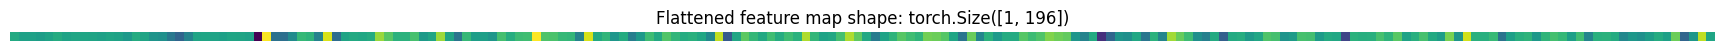

In [24]:
# Get a single flattened feature map
single_flattened_feature_map = image_out_of_conv_flattened_reshaped[:, :, 0] # index: (batch_size, number_of_patches, embedding_dimension)

# Plot the flattened feature map visually
plt.figure(figsize=(22, 22))
plt.imshow(single_flattened_feature_map.detach().numpy())
plt.title(f"Flattened feature map shape: {single_flattened_feature_map.shape}")
plt.axis(False);

In [25]:
# See the flattened feature map as a tensor
single_flattened_feature_map, single_flattened_feature_map.requires_grad, single_flattened_feature_map.shape

(tensor([[-0.0216, -0.0395, -0.0401, -0.0493, -0.0359, -0.0182, -0.0362, -0.0297,
          -0.0313, -0.0343, -0.0402, -0.0330, -0.0382, -0.0569, -0.0186, -0.0341,
          -0.0698, -0.0775, -0.1311, -0.1721, -0.1067, -0.0351, -0.0310, -0.0367,
          -0.0423, -0.0328, -0.0337, -0.0399, -0.3438,  0.1840, -0.1447, -0.1492,
          -0.0889,  0.0112,  0.0011, -0.1077,  0.1566, -0.1547, -0.0348, -0.0222,
          -0.0279, -0.0172,  0.1074,  0.0491, -0.0023, -0.0028,  0.0314, -0.0548,
          -0.0327,  0.1089, -0.0352, -0.1397,  0.0116, -0.0468, -0.0438, -0.0648,
           0.0291, -0.0135,  0.0187,  0.0238,  0.1865,  0.0398,  0.0364,  0.0112,
           0.0080, -0.1056,  0.1551, -0.0214,  0.0045, -0.0649, -0.0178, -0.1171,
          -0.0581,  0.0217, -0.0239,  0.0421,  0.0046, -0.0158, -0.0070, -0.0280,
          -0.0925,  0.1380, -0.1932, -0.0305,  0.0537,  0.0098, -0.0248,  0.0248,
          -0.0158,  0.0219, -0.0048,  0.1236,  0.0080, -0.0367, -0.0265,  0.0302,
           0.124

### Putting Altogether

In [26]:
class PatchEmbedding(nn.Module):
    """Turns a 2D input image into a 1D sequence learnable embedding vector.

    Args:
        in_channels (int): Number of color channels for the input images. Defaults to 3.
        patch_size (int): Size of patches to convert input image into. Defaults to 16.
        embedding_dim (int): Size of embedding to turn image into. Defaults to 768.
    """
    
    def __init__(self, in_channels: int = 3, patch_size: int = 16, embedding_dim: int = 768):
        super().__init__()
        
        self.patcher = nn.Conv2d(in_channels = in_channels,
                                 out_channels = embedding_dim,
                                 kernel_size = patch_size,
                                 stride = patch_size,
                                 padding=0)
        
        self.flatten = nn.Flatten(start_dim=2, end_dim=3)
        
    def forward(self,x):
        image_resolution = x.shape[-1]
        assert image_resolution % patch_size == 0, f"Input image size ({image_resolution}) is not divisible by patch size ({patch_size})"
        
        x_patched = self.patcher(x)
        x_flattened = self.flatten(x_patched)
        
        return x_flattened.permute(0, 2, 1) # [batch_size, P^2•C, N] -> [batch_size, N, P^2•C]
        

In [27]:
# try it on single image
set_seeds()

patchify = PatchEmbedding(in_channels=3, patch_size=16, embedding_dim=768)


print(f"Input image shape: {image.unsqueeze(0).shape}")
patch_embedded_image = patchify(image.unsqueeze(0))
print(f"Output patch shape: {patch_embedded_image.shape} -> [batch_size, num_patches, embedding_size]")

Input image shape: torch.Size([1, 3, 224, 224])
Output patch shape: torch.Size([1, 196, 768]) -> [batch_size, num_patches, embedding_size]


In [28]:
random_input_image = (1,3,224,224)
random_input_image_error = (1,3,250,250) # not divisible by patch size

summary(PatchEmbedding(),
        input_size=random_input_image,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
PatchEmbedding (PatchEmbedding)          [1, 3, 224, 224]     [1, 196, 768]        --                   True
├─Conv2d (patcher)                       [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
├─Flatten (flatten)                      [1, 768, 14, 14]     [1, 768, 196]        --                   --
Total params: 590,592
Trainable params: 590,592
Non-trainable params: 0
Total mult-adds (M): 115.76
Input size (MB): 0.60
Forward/backward pass size (MB): 1.20
Params size (MB): 2.36
Estimated Total Size (MB): 4.17

### 4.6 Token Embedding

In [29]:
print(patch_embedded_image)
print(f"patch embedding shape: {patch_embedded_image.shape} -> [batch_size, num_patches, embedding_size]")

tensor([[[-0.0401, -0.0100, -0.0392,  ...,  0.0325, -0.0079,  0.0180],
         [-0.0595, -0.0067, -0.0510,  ...,  0.0248, -0.0055,  0.0226],
         [-0.0726, -0.0081, -0.0548,  ...,  0.0661, -0.0313,  0.0367],
         ...,
         [-0.6314,  0.1208, -0.2373,  ...,  0.4329, -0.2400,  0.1630],
         [-0.4423, -0.0585, -0.0581,  ...,  0.1002, -0.0822,  0.4985],
         [-0.0403, -0.0031, -0.0240,  ...,  0.0272, -0.0169,  0.0047]]],
       grad_fn=<PermuteBackward0>)
patch embedding shape: torch.Size([1, 196, 768]) -> [batch_size, num_patches, embedding_size]


In [30]:
batch_size = patch_embedded_image.shape[0]
embedding_dimension = patch_embedded_image.shape[-1]

class_token = nn.Parameter(torch.ones(batch_size,1,embedding_dimension),requires_grad=True)

print(class_token[:,:,:10])

print(f"Class token shape: {class_token.shape} -> [batch_size, 1, embedding_dimension]")

tensor([[[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]]], grad_fn=<SliceBackward0>)
Class token shape: torch.Size([1, 1, 768]) -> [batch_size, 1, embedding_dimension]


In [31]:
patch_embedded_image_with_class_embedding = torch.cat((class_token,patch_embedded_image),dim=1)
print(f"Patch embedded with class embedding shape: {patch_embedded_image_with_class_embedding.shape} -> [batch_size, num_patches + 1, embedding_size]")
print(patch_embedded_image_with_class_embedding)

Patch embedded with class embedding shape: torch.Size([1, 197, 768]) -> [batch_size, num_patches + 1, embedding_size]
tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
         [-0.0401, -0.0100, -0.0392,  ...,  0.0325, -0.0079,  0.0180],
         [-0.0595, -0.0067, -0.0510,  ...,  0.0248, -0.0055,  0.0226],
         ...,
         [-0.6314,  0.1208, -0.2373,  ...,  0.4329, -0.2400,  0.1630],
         [-0.4423, -0.0585, -0.0581,  ...,  0.1002, -0.0822,  0.4985],
         [-0.0403, -0.0031, -0.0240,  ...,  0.0272, -0.0169,  0.0047]]],
       grad_fn=<CatBackward0>)


### 4.7 Potitional Embedding

In [32]:
# View the sequence of patch embeddings with the prepended class embedding
patch_embedded_image_with_class_embedding, patch_embedded_image_with_class_embedding.shape

(tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
          [-0.0401, -0.0100, -0.0392,  ...,  0.0325, -0.0079,  0.0180],
          [-0.0595, -0.0067, -0.0510,  ...,  0.0248, -0.0055,  0.0226],
          ...,
          [-0.6314,  0.1208, -0.2373,  ...,  0.4329, -0.2400,  0.1630],
          [-0.4423, -0.0585, -0.0581,  ...,  0.1002, -0.0822,  0.4985],
          [-0.0403, -0.0031, -0.0240,  ...,  0.0272, -0.0169,  0.0047]]],
        grad_fn=<CatBackward0>),
 torch.Size([1, 197, 768]))

In [33]:
# get number of patches
number_of_patches = int((height * width) / patch_size**2)

# get embedding dimension
embedding_dimension = patch_embedded_image_with_class_embedding.shape[2]

# create the learnable 1D position embedding parameter
position_embedding = nn.Parameter(torch.ones(1,number_of_patches + 1, embedding_dimension), requires_grad=True)


print(position_embedding[:,:10,:10])
print(position_embedding.shape)





tensor([[[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]]], grad_fn=<SliceBackward0>)
torch.Size([1, 197, 768])


In [34]:
# Add the position embedding to the patch and class token embedding
patch_and_position_embedding = patch_embedded_image_with_class_embedding + position_embedding
print(patch_and_position_embedding)
print(f"Patch embeddings, class token prepended and positional embeddings added shape: {patch_and_position_embedding.shape} -> [batch_size, number_of_patches, embedding_dimension]")

tensor([[[2.0000, 2.0000, 2.0000,  ..., 2.0000, 2.0000, 2.0000],
         [0.9599, 0.9900, 0.9608,  ..., 1.0325, 0.9921, 1.0180],
         [0.9405, 0.9933, 0.9490,  ..., 1.0248, 0.9945, 1.0226],
         ...,
         [0.3686, 1.1208, 0.7627,  ..., 1.4329, 0.7600, 1.1630],
         [0.5577, 0.9415, 0.9419,  ..., 1.1002, 0.9178, 1.4985],
         [0.9597, 0.9969, 0.9760,  ..., 1.0272, 0.9831, 1.0047]]],
       grad_fn=<AddBackward0>)
Patch embeddings, class token prepended and positional embeddings added shape: torch.Size([1, 197, 768]) -> [batch_size, number_of_patches, embedding_dimension]


### 4.8 putting all together

In [35]:
set_seeds()

# set patch size
patch_size = 16

# print shape of original tensor and get the dimension
print(f"Image tensor shape: {image.shape}")
height,width = image.shape[1], image.shape[2]


# get image tensor and add batch dimension
X = image.unsqueeze(0)
print(f"Image tensor with batch dimension shape: {X.shape}")

# create patch embedding layer
patch_embedding = PatchEmbedding(in_channels=3, patch_size=patch_size,embedding_dim=768)

# pass image through embedding layer
patch_embedding = patch_embedding(X)
print(f"Patch embedding shape: {patch_embedding.shape} -> [batch_size, number_of patches, embedding_dimension]")

# create token embedding
batch_size = patch_embedding.shape[0]
embedding_dimension = patch_embedding.shape[-1]
class_token = nn.Parameter(torch.ones(batch_size,1,embedding_dimension),requires_grad=True)
print(f"class token shape: {class_token.shape} -> [batch_size, 1, embedding_dimension]")

# prepend class token to patch embedding
patch_embedding_class_token = torch.cat((class_token,patch_embedding),dim=1)
print(f"Patch embedding with class token shape: {patch_embedding_class_token.shape} -> [batch_size, number_of_patches + 1, embedding_dimension]")

# create position embedding
number_of_patches = int((height * width) / patch_size**2)
postition_embedding  = nn.Parameter(torch.ones(1,number_of_patches + 1, embedding_dimension), requires_grad=True)

# add position embedding to patch embedding with class token
patch_and_position_embedding = patch_embedding_class_token + postition_embedding
print(f"Patch embedding with class token and position embedding shape: {patch_and_position_embedding.shape} -> [batch_size, number_of_patches + 1, embedding_dimension]")


Image tensor shape: torch.Size([3, 224, 224])
Image tensor with batch dimension shape: torch.Size([1, 3, 224, 224])
Patch embedding shape: torch.Size([1, 196, 768]) -> [batch_size, number_of patches, embedding_dimension]
class token shape: torch.Size([1, 1, 768]) -> [batch_size, 1, embedding_dimension]
Patch embedding with class token shape: torch.Size([1, 197, 768]) -> [batch_size, number_of_patches + 1, embedding_dimension]
Patch embedding with class token and position embedding shape: torch.Size([1, 197, 768]) -> [batch_size, number_of_patches + 1, embedding_dimension]


## 5 Multihead Attention

In [36]:
# creating the multihead attention layer
class MultiheadSelfAttentionBlock(nn.Module):
    """Creates a multi-head self-attention block ("MSA block" for short).
    """
    
    # initialize the class with hyperparameter from table 1
    def __init__(self,
                 embedding_dim: int = 768,
                 num_heads: int = 12,
                 attn_dropout: float = 0.0):
        super().__init__()
        
        # create the norm layer (LN)
        self.layer_norm = nn.LayerNorm(normalized_shape=embedding_dim)
        
        # create the Multi-head self attention
        self.multihead_attn = nn.MultiheadAttention(embed_dim = embedding_dim,
                                                    num_heads = num_heads,
                                                    dropout = attn_dropout,
                                                    batch_first = True) # batch_first = True -> (batch_size, seq_len, embedding_dim)
    
    # create the forward() method to pass data through layer
    def forward(self,x):
        x = self.layer_norm(x)
        attn_output, _ = self.multihead_attn(query=x,key=x,value=x,need_weights=False) # don't need attention weights for ViT
        return attn_output
    
    

In [37]:
# create an instance of MSABlock
multihead_self_attention_block = MultiheadSelfAttentionBlock(embedding_dim=768,num_heads=12)

# pass patch and position image embedding trough MSABlock
patched_image_through_msa_block = multihead_self_attention_block(patch_and_position_embedding)
print(f"Input shape of MSA block: {patch_and_position_embedding.shape}")
print(f"Output shape MSA block: {patched_image_through_msa_block.shape}")


Input shape of MSA block: torch.Size([1, 197, 768])
Output shape MSA block: torch.Size([1, 197, 768])


## 6 Multi Layer Perceptron

In [38]:
# create a class that inherited from nn.Module
class MLPBlock(nn.Module):
    """Creates a layer normalized multilayer perceptron block ("MLP block" for short)."""
    # initialize the class with hypermarameters from table 1 and 3
    def __init__(self,
                 embedding_dim:int=768,
                 mlp_size:int=3072,
                 dropout:float=0.1):
        super().__init__()
        
        # create the norm layer LN
        self.layer_norm = nn.LayerNorm(normalized_shape=embedding_dim)
        
        # create the multilayer perceptron (MLP) layer(s)
        self.mlp = nn.Sequential(
            nn.Linear(in_features=embedding_dim,out_features=mlp_size),
            nn.GELU(),
            nn.Dropout(p=dropout),
            nn.Linear(in_features=mlp_size,out_features=embedding_dim),
            nn.Dropout(p=dropout)
        )
    def forward(self,x):
        x = self.layer_norm(x)
        x = self.mlp(x)
        return x
    
    

In [39]:
# test masukkan ke MLP
mlp_block = MLPBlock(embedding_dim=768,
                     mlp_size=3072,
                     dropout=0.1)

patched_image_through_mlp_block = mlp_block(patched_image_through_msa_block)
print(f"Input shape of MLP block: {patched_image_through_msa_block.shape}")
print(f"Output shape MLP block: {patched_image_through_mlp_block.shape}")

Input shape of MLP block: torch.Size([1, 197, 768])
Output shape MLP block: torch.Size([1, 197, 768])


## 7. Creating the Transformer Encoder block

In [40]:
# create a class that inherits from nn.Module
class TransformerEncoderBlock(nn.Module):
    """Create a Transformer Encoder block,"""
    # initialized with hyperparameter
    def __init__(self,
                 embedding_dim:int=768,
                 num_heads: int=12,
                 mlp_size:int=3072,
                 mlp_dropout:float=0.1,
                 attn_dropout:float=0):
        super().__init__()
        
        # create MSA block
        self.msa_block = MultiheadSelfAttentionBlock(embedding_dim=embedding_dim,
                                                     num_heads=num_heads,
                                                     attn_dropout=attn_dropout)
        
        # create MLP block
        self.mlp_block = MLPBlock(embedding_dim=embedding_dim,
                                  mlp_size=mlp_size,
                                  dropout=mlp_dropout)
        
        
    # create forward() method
    def forward(self,x):
        x = self.msa_block(x) + x
        x = self.mlp_block(x) + x 
        
        return x

In [41]:
# create an instance of TransformerEncoderBlodk
transformer_encoder_block = TransformerEncoderBlock()

summary(model=transformer_encoder_block,
        input_size=(1,197,768),
        col_names = ["input_size", "output_size", "num_params", "trainable"],
        col_width = 20,
        row_settings = ["var_names"])

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderBlock (TransformerEncoderBlock)  [1, 197, 768]        [1, 197, 768]        --                   True
├─MultiheadSelfAttentionBlock (msa_block)          [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─MultiheadAttention (multihead_attn)         --                   [1, 197, 768]        2,362,368            True
├─MLPBlock (mlp_block)                             [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─Sequential (mlp)                            [1, 197, 768]        [1, 197, 768]        --                   True
│    │    └─Linear (0)                     

In [42]:
# Create the same as above with torch.nn.TransformerEncoderLayer()
torch_transformer_encoder_layer = nn.TransformerEncoderLayer(d_model=768, # Hidden size D from Table 1 for ViT-Base
                                                             nhead=12, # Heads from Table 1 for ViT-Base
                                                             dim_feedforward=3072, # MLP size from Table 1 for ViT-Base
                                                             dropout=0.1, # Amount of dropout for dense layers from Table 3 for ViT-Base
                                                             activation="gelu", # GELU non-linear activation
                                                             batch_first=True, # Do our batches come first?
                                                             norm_first=True) # Normalize first or after MSA/MLP layers?

torch_transformer_encoder_layer

TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
  )
  (linear1): Linear(in_features=768, out_features=3072, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=3072, out_features=768, bias=True)
  (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (dropout1): Dropout(p=0.1, inplace=False)
  (dropout2): Dropout(p=0.1, inplace=False)
)

In [43]:
# # Get the output of PyTorch's version of the Transformer Encoder (uncomment for full output)
summary(model=torch_transformer_encoder_layer,
         input_size=(1, 197, 768), # (batch_size, num_patches, embedding_dimension)
         col_names=["input_size", "output_size", "num_params", "trainable"],
         col_width=20,
         row_settings=["var_names"])

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderLayer (TransformerEncoderLayer)  [1, 197, 768]        [1, 197, 768]        --                   True
├─LayerNorm (norm1)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─MultiheadAttention (self_attn)                   [1, 197, 768]        [1, 197, 768]        2,362,368            True
├─Dropout (dropout1)                               [1, 197, 768]        [1, 197, 768]        --                   --
├─LayerNorm (norm2)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─Linear (linear1)                                 [1, 197, 768]        [1, 197, 3072]       2,362,368            True
├─Dropout (dropout)                                [1, 197, 3072]       [1, 197, 3072]       --                   --
├─Linear (linear2)                             

## 8. Putting it all together to create ViT

In [44]:
# 1. Create a ViT class that inherits from nn.Module
class ViT(nn.Module):
    """Creates a Vision Transformer architecture with ViT-Base hyperparameters by default."""
    # 2. Initialize the class with hyperparameters from Table 1 and Table 3
    def __init__(self,
                 img_size:int=224, # Training resolution from Table 3 in ViT paper
                 in_channels:int=3, # Number of channels in input image
                 patch_size:int=16, # Patch size
                 num_transformer_layers:int=12, # Layers from Table 1 for ViT-Base
                 embedding_dim:int=768, # Hidden size D from Table 1 for ViT-Base
                 mlp_size:int=3072, # MLP size from Table 1 for ViT-Base
                 num_heads:int=12, # Heads from Table 1 for ViT-Base
                 attn_dropout:float=0, # Dropout for attention projection
                 mlp_dropout:float=0.1, # Dropout for dense/MLP layers
                 embedding_dropout:float=0.1, # Dropout for patch and position embeddings
                 num_classes:int=1000): # Default for ImageNet but can customize this
        super().__init__() # don't forget the super().__init__()!

        # 3. Make the image size is divisible by the patch size
        assert img_size % patch_size == 0, f"Image size must be divisible by patch size, image size: {img_size}, patch size: {patch_size}."

        # 4. Calculate number of patches (height * width/patch^2)
        self.num_patches = (img_size * img_size) // patch_size**2

        # 5. Create learnable class embedding (needs to go at front of sequence of patch embeddings)
        self.class_embedding = nn.Parameter(data=torch.randn(1, 1, embedding_dim),
                                            requires_grad=True)

        # 6. Create learnable position embedding
        self.position_embedding = nn.Parameter(data=torch.randn(1, self.num_patches+1, embedding_dim),
                                               requires_grad=True)

        # 7. Create embedding dropout value
        self.embedding_dropout = nn.Dropout(p=embedding_dropout)

        # 8. Create patch embedding layer
        self.patch_embedding = PatchEmbedding(in_channels=in_channels,
                                              patch_size=patch_size,
                                              embedding_dim=embedding_dim)

        # 9. Create Transformer Encoder blocks (we can stack Transformer Encoder blocks using nn.Sequential())
        # Note: The "*" means "all"
        self.transformer_encoder = nn.Sequential(*[TransformerEncoderBlock(embedding_dim=embedding_dim,
                                                                            num_heads=num_heads,
                                                                            mlp_size=mlp_size,
                                                                            mlp_dropout=mlp_dropout) for _ in range(num_transformer_layers)])

        # 10. Create classifier head
        self.classifier = nn.Sequential(
            nn.LayerNorm(normalized_shape=embedding_dim),
            nn.Linear(in_features=embedding_dim,
                      out_features=num_classes)
        )

    # 11. Create a forward() method
    def forward(self, x):

        # 12. Get batch size
        batch_size = x.shape[0]

        # 13. Create class token embedding and expand it to match the batch size (equation 1)
        class_token = self.class_embedding.expand(batch_size, -1, -1) # "-1" means to infer the dimension (try this line on its own)

        # 14. Create patch embedding (equation 1)
        x = self.patch_embedding(x)

        # 15. Concat class embedding and patch embedding (equation 1)
        x = torch.cat((class_token, x), dim=1)

        # 16. Add position embedding to patch embedding (equation 1)
        x = self.position_embedding + x

        # 17. Run embedding dropout (Appendix B.1)
        x = self.embedding_dropout(x)

        # 18. Pass patch, position and class embedding through transformer encoder layers (equations 2 & 3)
        x = self.transformer_encoder(x)

        # 19. Put 0 index logit through classifier (equation 4)
        x = self.classifier(x[:, 0]) # run on each sample in a batch at 0 index

        return x

In [45]:
batch_size = 32
class_token_embedding_single = nn.Parameter(data=torch.randn(1,1,768))
class_token_embedding_expanded = class_token_embedding_single.expand(batch_size,-1,-1)

print(f"Shape of class token embedding single {class_token_embedding_single.shape}")
print(f"Shape of class token embedding expanded {class_token_embedding_expanded.shape}")

Shape of class token embedding single torch.Size([1, 1, 768])
Shape of class token embedding expanded torch.Size([32, 1, 768])


In [46]:
set_seeds()

# Create a random tensor with same shape as a single image
random_image_tensor = torch.randn(1, 3, 224, 224) # (batch_size, color_channels, height, width)

# Create an instance of ViT with the number of classes we're working with (pizza, steak, sushi)
vit = ViT(num_classes=len(class_names))

# Pass the random image tensor to our ViT instance
vit(random_image_tensor)

tensor([[0.2525, 0.8748, 1.2374]], grad_fn=<AddmmBackward0>)

### 8.1 Visualize our Model

In [47]:
summary(vit,
        input_size=(32,3,224,224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
ViT (ViT)                                                    [32, 3, 224, 224]    [32, 3]              152,064              True
├─PatchEmbedding (patch_embedding)                           [32, 3, 224, 224]    [32, 196, 768]       --                   True
│    └─Conv2d (patcher)                                      [32, 3, 224, 224]    [32, 768, 14, 14]    590,592              True
│    └─Flatten (flatten)                                     [32, 768, 14, 14]    [32, 768, 196]       --                   --
├─Dropout (embedding_dropout)                                [32, 197, 768]       [32, 197, 768]       --                   --
├─Sequential (transformer_encoder)                           [32, 197, 768]       [32, 197, 768]       --                   True
│    └─TransformerEncoderBlock (0)                           [32, 197, 768]       [32, 197, 768]

## 9. Setting Up Training Code for our ViT model

### 9.1. Creating an Optimizer

In [ ]:
# use adam with weight decay

### 9.2 Loss Function

In [ ]:
# use torch.nn.CrossEntropyLoss()

###  9.3 Train Our Model

In [48]:
from going_modular.going_modular import engine 

optimizer = torch.optim.Adam(params=vit.parameters(),
                             lr=3e-3,
                             betas=(0.9,0.999),
                             weight_decay=0.3)

loss_fn = torch.nn.CrossEntropyLoss()

set_seeds()


results = engine.train(model=vit,
                       train_dataloader=train_dataloader,
                       test_dataloader=test_dataloader,
                       optimizer=optimizer,
                       loss_fn=loss_fn,
                       epochs=10,
                       device=device)

 10%|█         | 1/10 [00:08<01:19,  8.80s/it]

Epoch: 1 | train_loss: 5.1723 | train_acc: 0.3594 | test_loss: 4.9187 | test_acc: 0.2604


 20%|██        | 2/10 [00:15<01:01,  7.73s/it]

Epoch: 2 | train_loss: 2.0214 | train_acc: 0.3164 | test_loss: 1.5436 | test_acc: 0.2604


 30%|███       | 3/10 [00:22<00:51,  7.42s/it]

...

Epoch: 8 | train_loss: 1.1109 | train_acc: 0.3125 | test_loss: 1.1894 | test_acc: 0.2604


 90%|█████████ | 9/10 [01:08<00:07,  7.75s/it]

Epoch: 9 | train_loss: 1.1557 | train_acc: 0.3047 | test_loss: 1.0165 | test_acc: 0.5417


100%|██████████| 10/10 [01:15<00:00,  7.56s/it]

Epoch: 10 | train_loss: 1.2616 | train_acc: 0.2617 | test_loss: 1.3896 | test_acc: 0.2604


### 9.4 What our setup is missing

In [49]:
# learning rate warmup, learning rate decay, gradient clipping

### 9.5 Plot the loss curves of our ViT model

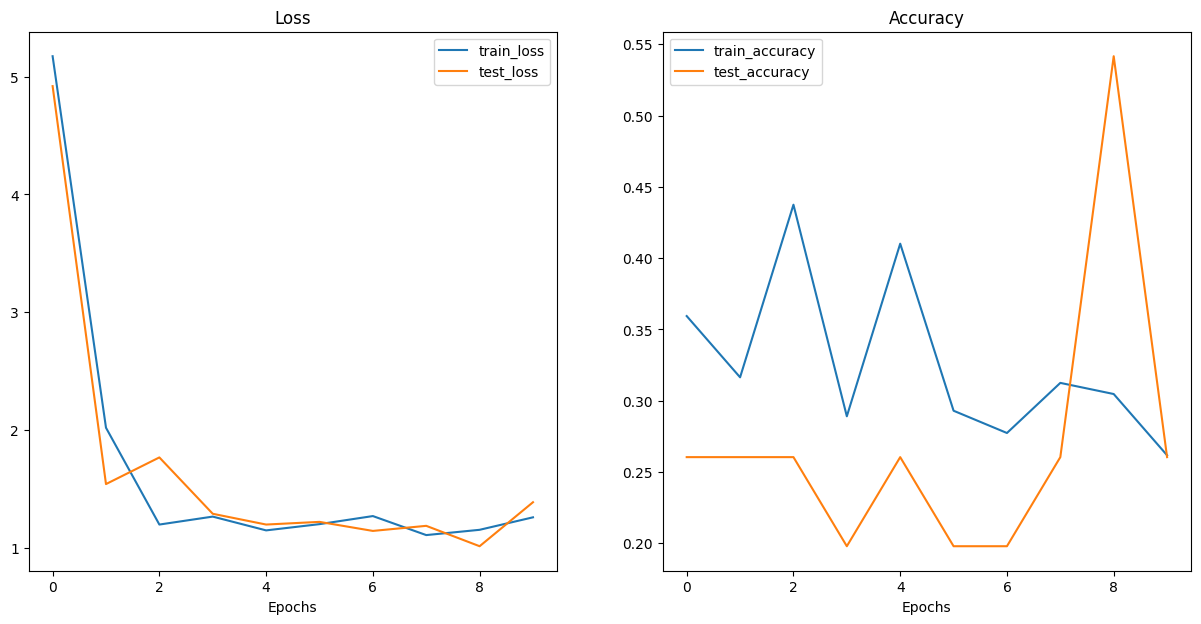

In [50]:
from helper_functions import plot_loss_curves

plot_loss_curves(results)

## 10 Using Pretrained Pytorch

In [51]:
import torch
import torchvision
print(torch.__version__)
print(torchvision.__version__)

2.14.0+cu130
0.29.0+cu130


In [52]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [ ]:
pretrained_vit_weights = torchvision.models.ViT_B_16_Weights.DEFAULT

pretrained_vit = torchvision.models.vit_b_16(weights=pretrained_vit_weights).to(device)

for parameter in pretrained_vit.parameters():
    parameter.requires_grad = False
    
set_seeds()
pretrained_vit.heads = nn.Linear(in_features=768, out_features=len(class_names)).to(device)

pretrained_vit

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /home/rayaa/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


 46%|████▌     | 153M/330M [02:14<02:32, 1.22MB/s] 

In [ ]:
summary(model=pretrained_vit,
         input_size=(32, 3, 224, 224), # (batch_size, color_channels, height, width)
         # col_names=["input_size"], # uncomment for smaller output
         col_names=["input_size", "output_size", "num_params", "trainable"],
         col_width=20,
         row_settings=["var_names"]
 )

In [ ]:
# preparing data for the pretrained ViT model
from helper_functions import download_data
image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path